# EDA

En este cuaderno se va a tratar el database para su comprensión y su manipulación en otros cuadernos.

## Carga del CSV

In [228]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
scaler = StandardScaler()

In [229]:
pd.set_option("display.max_columns", None)
LHC = pd.read_csv("atlas-higgs-challenge-2014-v2.csv", sep=',')


## Análisis del CSV

In [230]:
LHC.head(4)

,EventId,DER_mass_MMC,DER_mass_transverse_met_lep,DER_mass_vis,DER_pt_h,DER_deltaeta_jet_jet,DER_mass_jet_jet,DER_prodeta_jet_jet,DER_deltar_tau_lep,DER_pt_tot,DER_sum_pt,DER_pt_ratio_lep_tau,DER_met_phi_centrality,DER_lep_eta_centrality,PRI_tau_pt,PRI_tau_eta,PRI_tau_phi,PRI_lep_pt,PRI_lep_eta,PRI_lep_phi,PRI_met,PRI_met_phi,PRI_met_sumet,PRI_jet_num,PRI_jet_leading_pt,PRI_jet_leading_eta,PRI_jet_leading_phi,PRI_jet_subleading_pt,PRI_jet_subleading_eta,PRI_jet_subleading_phi,PRI_jet_all_pt,Weight,Label,KaggleSet,KaggleWeight
0,100000,138.470,51.655,97.827,27.980,0.91,124.711,2.666,3.064,41.928,197.760,1.582,1.396,0.2,32.638,1.017,0.381,51.626,2.273,-2.414,16.824,-0.277,258.733,2,67.435,2.150,0.444,46.062,1.24,-2.475,113.497,0.000814,s,t,0.002653
1,100001,160.937,68.768,103.235,48.146,-999.00,-999.000,-999.000,3.473,2.078,125.157,0.879,1.414,-999.0,42.014,2.039,-3.011,36.918,0.501,0.103,44.704,-1.916,164.546,1,46.226,0.725,1.158,-999.000,-999.00,-999.000,46.226,0.681042,b,t,2.233584
2,100002,-999.000,162.172,125.953,35.635,-999.00,-999.000,-999.000,3.148,9.336,197.814,3.776,1.414,-999.0,32.154,-0.705,-2.093,121.409,-0.953,1.052,54.283,-2.186,260.414,1,44.251,2.053,-2.028,-999.000,-999.00,-999.000,44.251,0.715742,b,t,2.347389
3,100003,143.905,81.417,80.943,0.414,-999.00,-999.000,-999.000,3.310,0.414,75.968,2.354,-1.285,-999.0,22.647,-1.655,0.010,53.321,-0.522,-3.100,31.082,0.060,86.062,0,-999.000,-999.000,-999.000,-999.000,-999.00,-999.000,-0.000,1.660654,b,t,5.446378


In [231]:
LHC.info()
# CSV de 818238 datos
# 35 columnas de información de las cuales 3 son string, es decir, contienen información, no valor.

<class 'pandas.DataFrame'>
RangeIndex: 818238 entries, 0 to 818237
Data columns (total 35 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   EventId                      818238 non-null  int64  
 1   DER_mass_MMC                 818238 non-null  float64
 2   DER_mass_transverse_met_lep  818238 non-null  float64
 3   DER_mass_vis                 818238 non-null  float64
 4   DER_pt_h                     818238 non-null  float64
 5   DER_deltaeta_jet_jet         818238 non-null  float64
 6   DER_mass_jet_jet             818238 non-null  float64
 7   DER_prodeta_jet_jet          818238 non-null  float64
 8   DER_deltar_tau_lep           818238 non-null  float64
 9   DER_pt_tot                   818238 non-null  float64
 10  DER_sum_pt                   818238 non-null  float64
 11  DER_pt_ratio_lep_tau         818238 non-null  float64
 12  DER_met_phi_centrality       818238 non-null  float64
 13  DER_lep_et

Se puede apreciar que no existe ningún valor Nan ya que todos tienen la misma cantidad de valores non-null que dimensión tiene el CSV. No obstante, que no haya valor Nan no significa que el CSV esté completo. Vease el apartado **Análisis del valor -999**

In [232]:
# solo para comprobar la información de cada columna de tipo string
print(LHC['Label'].unique())
print(LHC['KaggleSet'].unique())

<StringArray>
['s', 'b']
Length: 2, dtype: str
<StringArray>
['t', 'b', 'v', 'u']
Length: 4, dtype: str


### Significado de cada columna:

| Columna | Significado |
| --- | --- |
| EventId | Localizador para cada fila |
| Weight | Peso del evento (que se utiliza para calcular el AMS), normalizado sobre el dataset completo |
| Label | Etiqueta que representa si el evento es s (señal de Higgs) o b (señal de fondo) |
| KaggleSet | Los subconjuntos que se utilizarón en la competición siendo t el subconjunto de entrenamiento, b el subconjunto de validación y v el subconjunto de test final |
| KaggleWeight | Los pesos normalizados de cada subconjunto de KaggleSet |


**PRI (Variables primitivas)**

Son parámetros medidos directamente por el detector. Momentos y energías en GeV, ángulos $\phi$ en radianes, $\eta$ (pseudorapidez) adimensional. Para entender qué es cada cosa es necesario entender cómo surgen. 

En el HCL se coge partículas de hidrógeno sin electrones (es decir, protones) y se las hace chocar hasta detectar esos choques interesantes que generar el bosson de Higgs. Puede emerger de dos forma:
- Fusión de gluones: en el que sale un bosson de Higgs con  o 1 chorro.
- Fusión de bosones vectoriales (VBF): en el que 2 quarks emiten bossones que se fusionan en un Higgs, saliendo los 2 quarks como 2 chorros.

Por tanto la variable PRI_jet_num lo que permite es distinguir el modo de producción del bosson de Higgs.
Por otro lado, el bosson de Higgs tiene una desintegración de 10^(-22)segundos, por lo que la información de su existencia no viene determinada por su detección, sino por la detección de sus desintegraciones. Este bosson de Higgs se desintegra en dos Tau, que a su vez, uno se desintegra en hadrones (PRI_Tau_) y el otro se desintegra en muones o eletrones (PRI_lep). Agrupando la energía transversal total del choque en la variable PRI_met_sumet.

| Columna | Significado |
|---|---|
| PRI_tau_pt | Momento transversal del tau hadrónico |
| PRI_tau_eta | Pseudorapidez del tau hadrónico |
| PRI_tau_phi | Ángulo azimutal del tau hadrónico |
| PRI_lep_pt | Momento transversal del leptón (electrón o muón) |
| PRI_lep_eta | Pseudorapidez del leptón |
| PRI_lep_phi | Ángulo azimutal del leptón |
| PRI_met | Módulo de la energía transversal perdida (la que se llevan los neutrinos) |
| PRI_met_phi | Ángulo azimutal de la energía transversal perdida |
| PRI_met_sumet | Energía transversal total depositada en el detector |
| PRI_jet_num | Número de chorros (0, 1, 2 o 3; el 3 significa "3 o más") |
| PRI_jet_leading_pt | Momento transversal del chorro principal (mayor $p_T$) |
| PRI_jet_leading_eta | Pseudorapidez del chorro principal |
| PRI_jet_leading_phi | Ángulo azimutal del chorro principal |
| PRI_jet_subleading_pt | Momento transversal del segundo chorro |
| PRI_jet_subleading_eta | Pseudorapidez del segundo chorro |
| PRI_jet_subleading_phi | Ángulo azimutal del segundo chorro |
| PRI_jet_all_pt | Suma escalar del $p_T$ de todos los chorros |


**DER (Variables derivadas)**

Calculadas por los físicos a partir de las PRI. Notación: $\vec{p}_T = p_T(\cos\phi, \sin\phi)$ es el momento transversal como vector; $\Delta\phi$ se reduce siempre al intervalo $[-\pi, \pi]$; $j_1$ y $j_2$ son el chorro principal y el segundo chorro. Las masas suponen partículas sin masa ($m \approx 0$).

| Columna | Significado | Cálculo a partir de las PRI |
|---|---|---|
| DER_mass_MMC | Masa estimada del candidato a Higgs | Algoritmo *Missing Mass Calculator*: maximiza una verosimilitud sobre la cinemática de los neutrinos usando tau, leptón y MET. No tiene fórmula cerrada |
| DER_mass_transverse_met_lep | Masa transversal entre leptón y energía perdida | $\sqrt{2\, p_T^{lep}\, E_T^{miss}\,\left(1-\cos(\phi_{lep}-\phi_{met})\right)}$ |
| DER_mass_vis | Masa invariante visible de tau + leptón | $\sqrt{2\, p_T^{\tau}\, p_T^{lep}\,\left(\cosh(\eta_\tau-\eta_{lep})-\cos(\phi_\tau-\phi_{lep})\right)}$ |
| DER_pt_h | $p_T$ del candidato a Higgs | $\lVert \vec{p}_T^{\,\tau}+\vec{p}_T^{\,lep}+\vec{E}_T^{\,miss} \rVert$ |
| DER_deltaeta_jet_jet | Separación en $\eta$ entre los dos chorros | $\lvert \eta_{j_1}-\eta_{j_2} \rvert$ |
| DER_mass_jet_jet | Masa invariante de los dos chorros | $\sqrt{2\, p_T^{j_1}\, p_T^{j_2}\,\left(\cosh(\eta_{j_1}-\eta_{j_2})-\cos(\phi_{j_1}-\phi_{j_2})\right)}$ |
| DER_prodeta_jet_jet | Producto de las $\eta$ de los dos chorros | $\eta_{j_1}\cdot\eta_{j_2}$ |
| DER_deltar_tau_lep | Separación angular entre tau y leptón | $\sqrt{(\eta_\tau-\eta_{lep})^2+(\Delta\phi_{\tau,lep})^2}$ |
| DER_pt_tot | Módulo del $p_T$ total del evento | $\lVert \vec{p}_T^{\,\tau}+\vec{p}_T^{\,lep}+\vec{p}_T^{\,j_1}+\vec{p}_T^{\,j_2}+\vec{E}_T^{\,miss} \rVert$ |
| DER_sum_pt | Suma escalar de momentos transversales | $p_T^{\tau}+p_T^{lep}+$ PRI_jet_all_pt |
| DER_pt_ratio_lep_tau | Cociente de momentos leptón/tau | $p_T^{lep}\,/\,p_T^{\tau}$ |
| DER_met_phi_centrality | Indica si la MET apunta "entre" tau y leptón en $\phi$ (rango $[-\sqrt{2},\sqrt{2}]$) | $\dfrac{A+B}{\sqrt{A^2+B^2}}$, con $s=\operatorname{sgn}(\sin(\phi_\tau-\phi_{lep}))$, $A=s\,\sin(\phi_{met}-\phi_{lep})$, $B=s\,\sin(\phi_\tau-\phi_{met})$ |
| DER_lep_eta_centrality | Indica si el leptón está "entre" los dos chorros en $\eta$ (1 en el centro, $1/e$ en los chorros) | $\exp\!\left[-\dfrac{4}{(\eta_{j_1}-\eta_{j_2})^2}\left(\eta_{lep}-\dfrac{\eta_{j_1}+\eta_{j_2}}{2}\right)^2\right]$ |

### Análisis del valor -999

El significado físico sobre el valore -999 es equivalente a los valores faltantes o Nan. Por ello el el análisis del valor -999 equivale a la limpieza del data set 

In [233]:
print([col for col in LHC.columns if (LHC[col] == -999).any()])
print("\nCantidad de valores -999/Nan:")
print(f"- PRI_jet_leading_pt: {LHC["PRI_jet_leading_pt"].value_counts().get(-999,0)}/{LHC["PRI_jet_leading_pt"].count()} = {(LHC["PRI_jet_leading_pt"].value_counts().get(-999,0)/LHC["PRI_jet_leading_pt"].count()):.1%}")
print(f"- PRI_jet_leading_eta: {LHC["PRI_jet_leading_eta"].value_counts().get(-999,0)}/{LHC["PRI_jet_leading_eta"].count()} = {(LHC["PRI_jet_leading_eta"].value_counts().get(-999,0)/LHC["PRI_jet_leading_eta"].count()):.1%}")
print(f"- PRI_jet_leading_phi: {LHC["PRI_jet_leading_phi"].value_counts().get(-999,0)}/{LHC["PRI_jet_leading_phi"].count()} = {(LHC["PRI_jet_leading_phi"].value_counts().get(-999,0)/LHC["PRI_jet_leading_phi"].count()):.1%}")
print(f"- PRI_jet_subleading_pt: {LHC["PRI_jet_subleading_pt"].value_counts().get(-999,0)}/{LHC["PRI_jet_subleading_pt"].count()} = {(LHC["PRI_jet_subleading_pt"].value_counts().get(-999,0)/LHC["PRI_jet_subleading_pt"].count()):.1%}")
print(f"- PRI_jet_subleading_eta: {LHC["PRI_jet_subleading_eta"].value_counts().get(-999,0)}/{LHC["PRI_jet_subleading_eta"].count()} = {(LHC["PRI_jet_subleading_eta"].value_counts().get(-999,0)/LHC["PRI_jet_subleading_eta"].count()):.1%}")
print(f"- PRI_jet_subleading_phi: {LHC["PRI_jet_subleading_phi"].value_counts().get(-999,0)}/{LHC["PRI_jet_subleading_phi"].count()} = {(LHC["PRI_jet_subleading_phi"].value_counts().get(-999,0)/LHC["PRI_jet_subleading_phi"].count()):.1%}")
print(f"- DER_mass_MMC: {LHC["DER_mass_MMC"].value_counts().get(-999,0)}/{LHC["DER_mass_MMC"].count()} = {(LHC["DER_mass_MMC"].value_counts().get(-999,0)/LHC["DER_mass_MMC"].count()):.1%}")
print(f"- DER_deltaeta_jet_jet: {LHC["DER_deltaeta_jet_jet"].value_counts().get(-999,0)}/{LHC["DER_deltaeta_jet_jet"].count()} = {(LHC["DER_deltaeta_jet_jet"].value_counts().get(-999,0)/LHC["DER_deltaeta_jet_jet"].count()):.1%}")
print(f"- DER_mass_jet_jet: {LHC["DER_mass_jet_jet"].value_counts().get(-999,0)}/{LHC["DER_mass_jet_jet"].count()} = {(LHC["DER_mass_jet_jet"].value_counts().get(-999,0)/LHC["DER_mass_jet_jet"].count()):.1%}")
print(f"- DER_prodeta_jet_jet: {LHC["DER_prodeta_jet_jet"].value_counts().get(-999,0)}/{LHC["DER_prodeta_jet_jet"].count()} = {(LHC["DER_prodeta_jet_jet"].value_counts().get(-999,0)/LHC["DER_prodeta_jet_jet"].count()):.1%}")
print(f"- DER_lep_eta_centrality: {LHC["DER_lep_eta_centrality"].value_counts().get(-999,0)}/{LHC["DER_lep_eta_centrality"].count()} = {(LHC["DER_lep_eta_centrality"].value_counts().get(-999,0)/LHC["DER_lep_eta_centrality"].count()):.1%}")


['DER_mass_MMC', 'DER_deltaeta_jet_jet', 'DER_mass_jet_jet', 'DER_prodeta_jet_jet', 'DER_lep_eta_centrality', 'PRI_jet_leading_pt', 'PRI_jet_leading_eta', 'PRI_jet_leading_phi', 'PRI_jet_subleading_pt', 'PRI_jet_subleading_eta', 'PRI_jet_subleading_phi']

Cantidad de valores -999/Nan:
- PRI_jet_leading_pt: 327371/818238 = 40.0%
- PRI_jet_leading_eta: 327371/818238 = 40.0%
- PRI_jet_leading_phi: 327371/818238 = 40.0%
- PRI_jet_subleading_pt: 580253/818238 = 70.9%
- PRI_jet_subleading_eta: 580253/818238 = 70.9%
- PRI_jet_subleading_phi: 580253/818238 = 70.9%
- DER_mass_MMC: 124602/818238 = 15.2%
- DER_deltaeta_jet_jet: 580253/818238 = 70.9%
- DER_mass_jet_jet: 580253/818238 = 70.9%
- DER_prodeta_jet_jet: 580253/818238 = 70.9%
- DER_lep_eta_centrality: 580253/818238 = 70.9%


El análisis de estos valores -999 tiene todo el sentido, si no existe primer chorro, no existe el segundo. Proporción de CSV con 0 chorros 40%, 1 chorro 30% y 2 chorros 30%. Por tanto la cantidad de boson de Higgs que proceden de la fusión de bosones vectoriales son el 30% del CSV (2 chorros), y de la fusión de gluones es el 70%. Por tanto no se va a tratar como valores faltantes, sino como información clasificatoria, que simplemente el MLP no tendrá que utilizar.

Con esa misma argumentación, la proporción de las variables DER tienen sentido, ya que no se podrá calcular la misma cantidad de fórmulas que necesiten información de los dos chorros.

## Ajuste y normalización

Una vez analizado que el csv está limpio (aunque se tendrá que tener en cuenta cómo manipular los valores -999), se va a proceder a reestructurar y normalizar el csv.

Hay que tener en cuenta que para el desarrollo de este proyecto se van a necesitar tres conjuntos del data set para entrenar, ajustar los hiperparámetros y testear el MLP para comprobar la hipótesis. Por tanto, la normalización va a ser de cada conjunto del LHC diferenciado por la variable KaggleSet, que ya los diferencia en estos tres tipos.

### Distribución y correlaciones de los datos

Para poder visualizar de forma correcta las distribuciones, se va a reemplazar las valores -999 a NaN.

In [234]:
# Los -999 se tratan como NaN para que no deformen los histogramas ni las correlaciones
LHC = LHC.replace(-999, np.nan)

Diviendo en los tres conjuntos:

In [235]:
# Se hace la separación por la etiqueta de entrenamiento "t", ajuste "b" y test "v".
Entrenamiento = LHC[LHC["KaggleSet"] == "t"]
Ajuste = LHC[LHC["KaggleSet"] == "b"]
Test = LHC[LHC["KaggleSet"] == "v"]

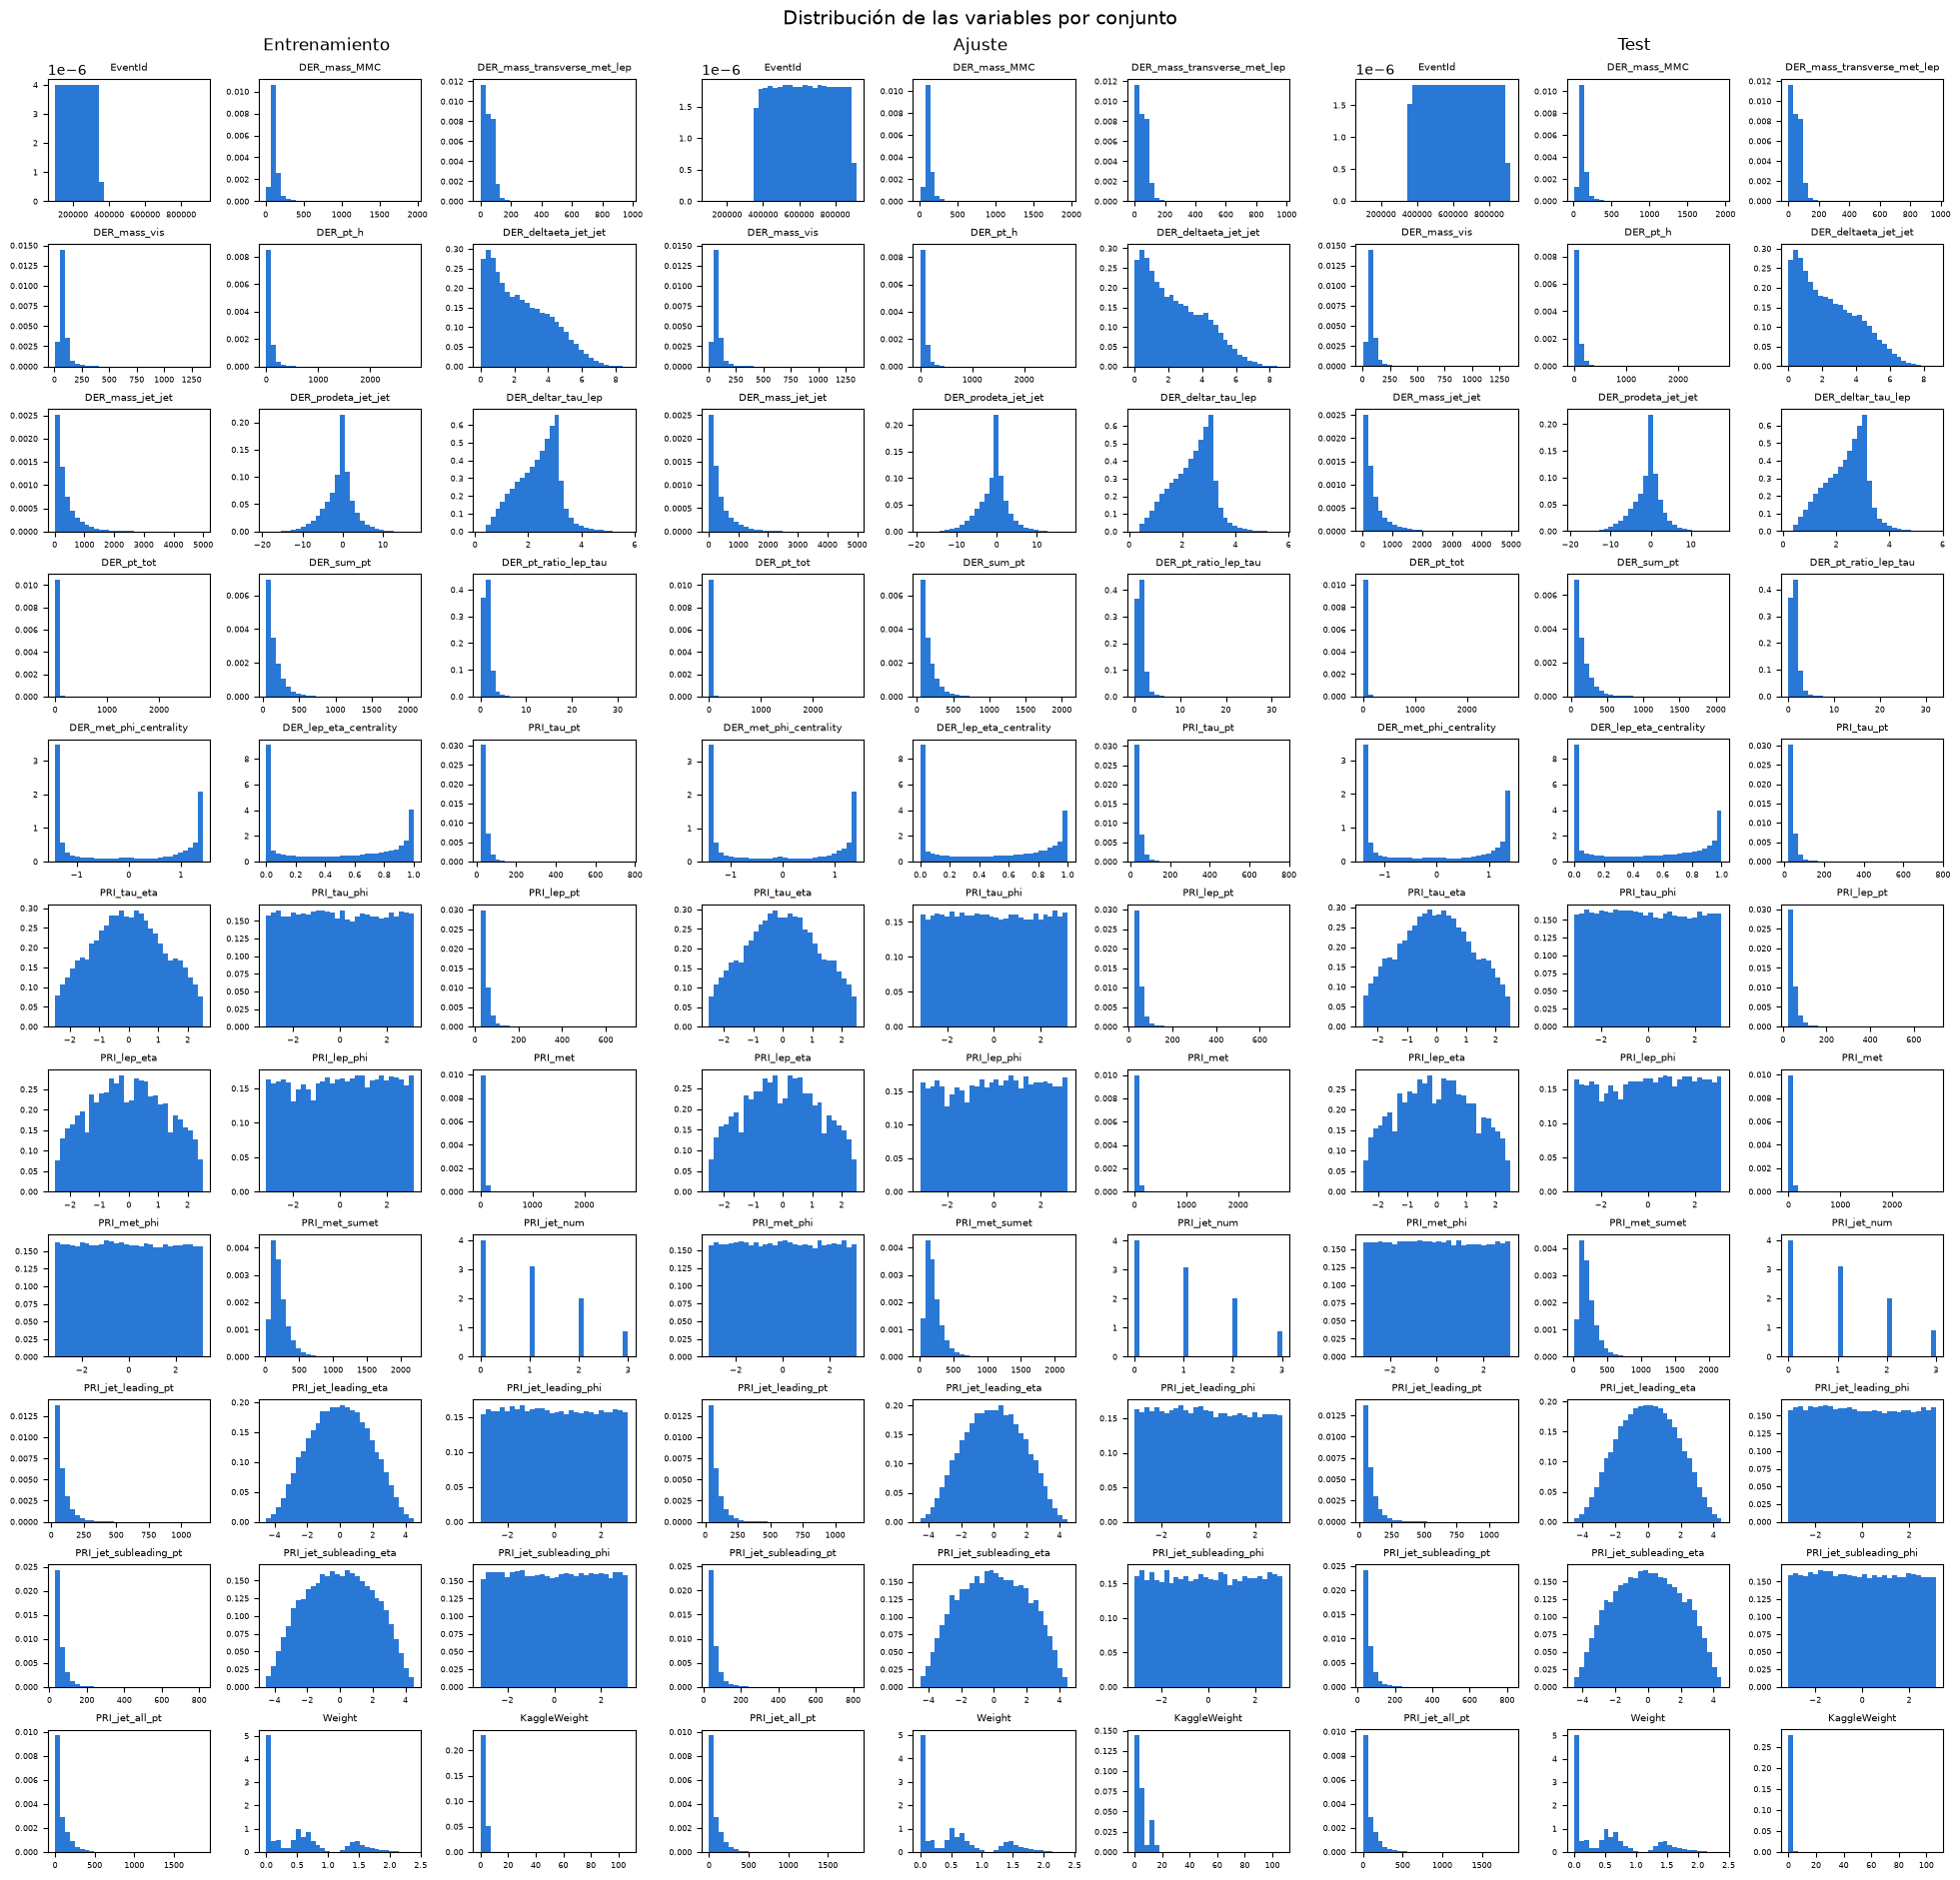

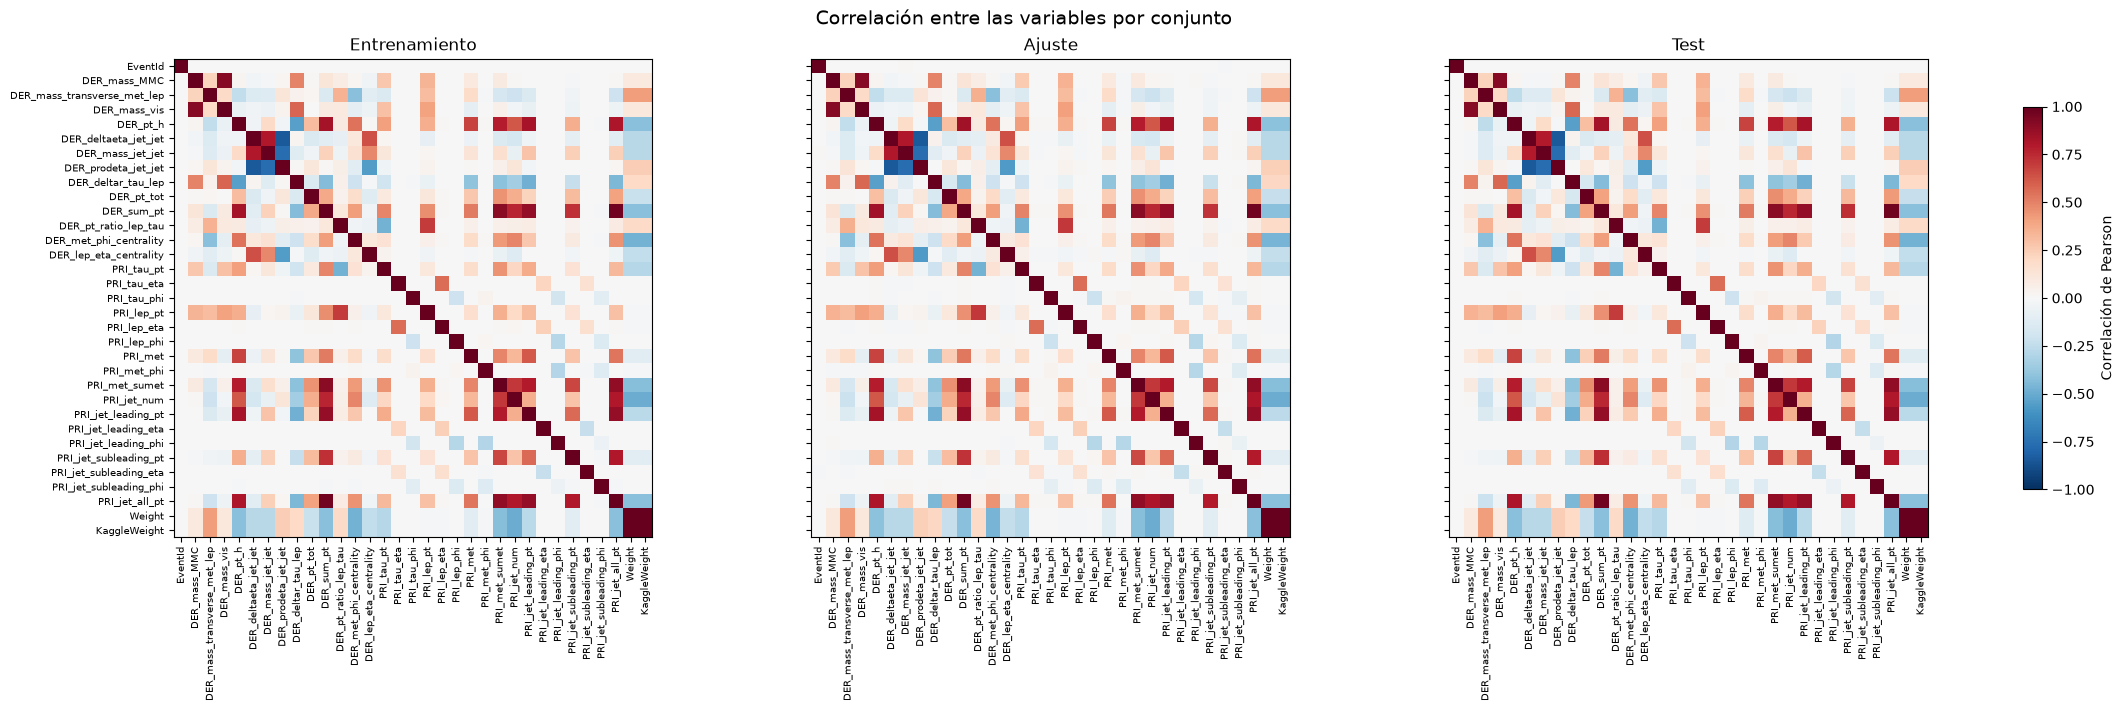

In [236]:
conjuntos = {"Entrenamiento": Entrenamiento, "Ajuste": Ajuste, "Test": Test}

# Solo las columnas numéricas (Label y KaggleSet son texto y no se pueden representar ni correlacionar)
variables = LHC.select_dtypes(include="number").columns.tolist()

columnas = 3
filas = int(np.ceil(len(variables) / columnas))


# HISTOGRAMAS: los tres conjuntos alineados uno al lado del otro
fig = plt.figure(figsize=(19.5, 1.7 * filas), layout="constrained")
subfiguras = fig.subfigures(1, len(conjuntos))

for subfigura, (nombre, datos) in zip(subfiguras, conjuntos.items()):
    subfigura.suptitle(nombre, fontsize=12)
    axes = subfigura.subplots(filas, columnas).ravel()

    for ax, variable in zip(axes, variables):
        # Mismos intervalos en los tres conjuntos para poder compararlos
        intervalos = np.histogram_bin_edges(LHC[variable].dropna(), bins=30)
        ax.hist(datos[variable].dropna(), bins=intervalos, density=True, color="#2a78d6")
        ax.set_title(variable, fontsize=7)
        ax.tick_params(labelsize=6)

    for ax in axes[len(variables):]:
        ax.set_visible(False)

fig.suptitle("Distribución de las variables por conjunto", fontsize=14)
plt.show()


# MAPAS DE CORRELACIONES: los tres conjuntos alineados uno al lado del otro
fig, axes = plt.subplots(1, len(conjuntos), figsize=(22, 7), layout="constrained")

for ax, (nombre, datos) in zip(axes, conjuntos.items()):
    corr = datos[variables].corr()
    imagen = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
    ax.set_title(nombre)

# Solo se dejan los nombres del eje Y en el primer mapa
for ax in axes[1:]:
    ax.set_yticks(range(len(corr)), [])

fig.colorbar(imagen, ax=axes, label="Correlación de Pearson", shrink=0.8)
fig.suptitle("Correlación entre las variables por conjunto", fontsize=14)
plt.show()

Estas gráficas sirven para saber cómo manipular los datos, es decir, hay variables que son muy asimétricas y que en el futuro pueden generar que no se manipulen de igual manera, dando como irrelevantes a los de menor valor numérico. Por ello al hacer la normalización se va a tener que implementar un logaritmo para igualar esos valores y poder tomarlos en cuenta. Hay que tener en cuenta dos cosas:
- No en todas las variables, ya que Weight y Kaggleweight son solo valores de entrada para el AMS. Tampoco las variables de centrality, ya que al estar acotadas no se debería de implementar un logaritmo (ya que estas son para colas largas). Ni en general aquellas variables que no representen unos valores en forma de cola larga, es decir, que sean simétricas.

In [237]:
# Comprobación numérica asimetría para comprobar que variables se tienen que modificar
transformaciones = LHC.select_dtypes(include="number").columns.drop(["EventId", "Weight", "KaggleWeight"]).tolist()

resumen = pd.DataFrame({
    "Asimetría original": [Entrenamiento[c].skew() for c in transformaciones],
}, index=list(transformaciones))
display(resumen)

,Asimetría original
DER_mass_MMC,3.807351
DER_mass_transverse_met_lep,1.219211
DER_mass_vis,3.790262
DER_pt_h,2.541885
DER_deltaeta_jet_jet,0.577082
DER_mass_jet_jet,2.457852
DER_prodeta_jet_jet,-0.328458
DER_deltar_tau_lep,-0.215782
DER_pt_tot,10.579309
DER_sum_pt,2.320647


Por otro lado, se van a generar las gráficas de comparación entre señal y fondo para analizar si se logra ver alguna diferencia entre las características de estos grupos para intentar intuir si se van a poder diferenciar o no en los modelos que se van a utilizar para desarrollar este proyecto.

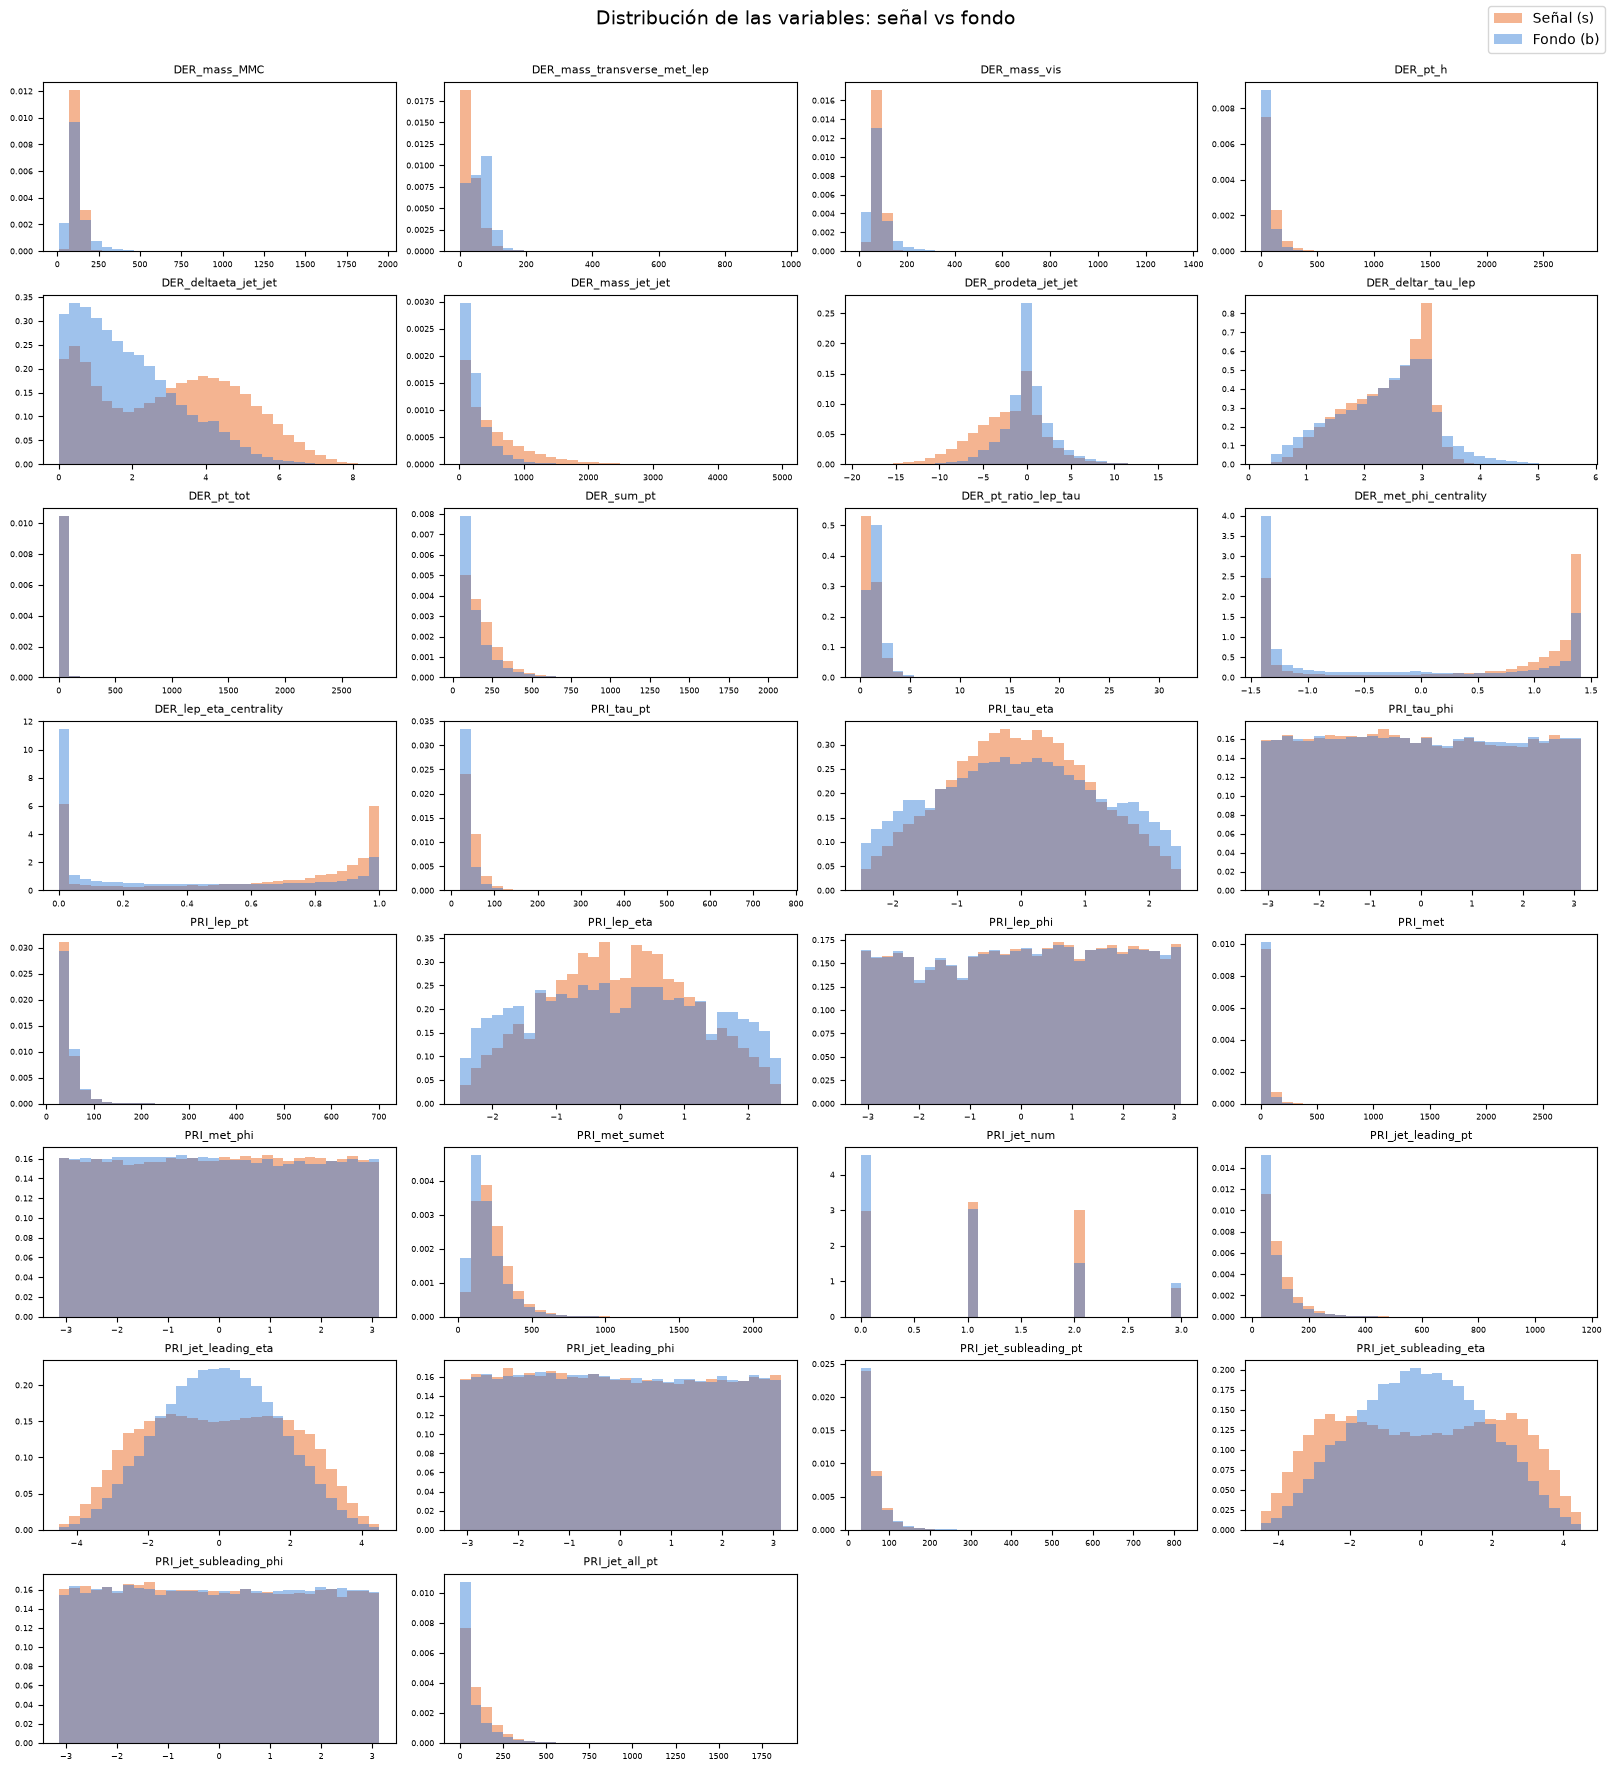

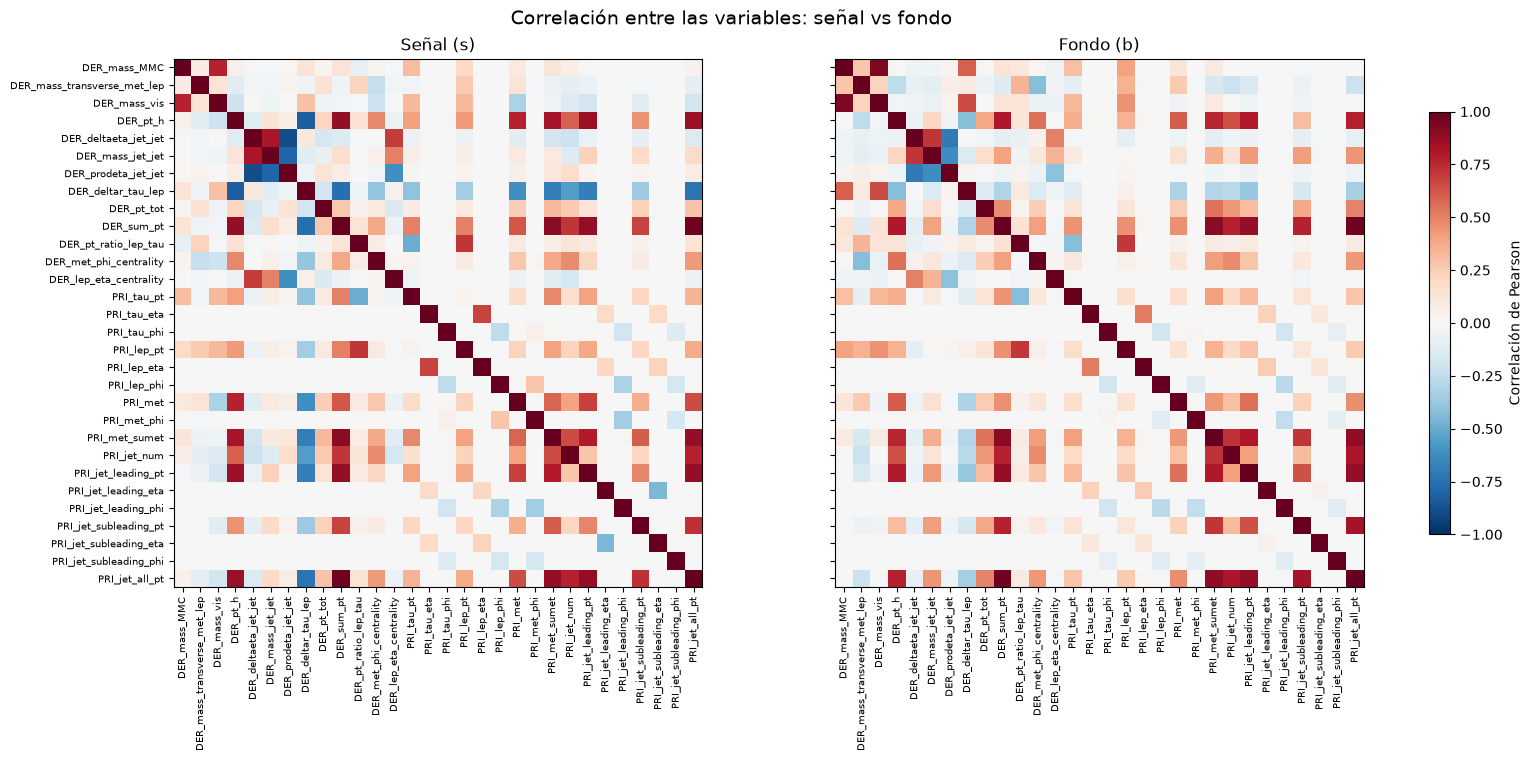

In [238]:
# Se separa todo el LHC según la etiqueta: "s" señal de Higgs y "b" fondo
grupos = {"Señal (s)": LHC[LHC["Label"] == "s"], "Fondo (b)": LHC[LHC["Label"] == "b"]}
colores = {"Señal (s)": "#e8590c", "Fondo (b)": "#2a78d6"}

# Solo las variables PRI y DER (se quitan el identificador y los pesos, que no son características físicas)
variables = LHC.select_dtypes(include="number").columns.drop(["EventId", "Weight", "KaggleWeight"]).tolist()

columnas = 4
filas = int(np.ceil(len(variables) / columnas))


# HISTOGRAMAS: señal y fondo superpuestos en el mismo gráfico
fig, axes = plt.subplots(filas, columnas, figsize=(16, 2.2 * filas), layout="constrained")
axes = axes.ravel()

for ax, variable in zip(axes, variables):
    # Mismos intervalos en señal y fondo para poder compararlos
    intervalos = np.histogram_bin_edges(LHC[variable].dropna(), bins=30)
    for nombre, datos in grupos.items():
        # alpha hace los colores translúcidos para que se vean ambas distribuciones donde se solapan
        ax.hist(datos[variable].dropna(), bins=intervalos, density=True,
                color=colores[nombre], alpha=0.45, label=nombre)
    ax.set_title(variable, fontsize=8)
    ax.tick_params(labelsize=6)

for ax in axes[len(variables):]:
    ax.set_visible(False)

# Una sola leyenda para toda la figura
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper right", fontsize=10)
fig.suptitle("Distribución de las variables: señal vs fondo", fontsize=14)
plt.show()


# MAPAS DE CORRELACIONES: señal y fondo alineados uno al lado del otro
fig, axes = plt.subplots(1, len(grupos), figsize=(16, 7.5), layout="constrained")

for ax, (nombre, datos) in zip(axes, grupos.items()):
    corr = datos[variables].corr()
    imagen = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
    ax.set_title(nombre)

# Solo se dejan los nombres del eje Y en el primer mapa
for ax in axes[1:]:
    ax.set_yticks(range(len(corr)), [])

fig.colorbar(imagen, ax=axes, label="Correlación de Pearson", shrink=0.8)
fig.suptitle("Correlación entre las variables: señal vs fondo", fontsize=14)
plt.show()

### Normalización de los CSV

Como se ha analizado en el anterior apartado, para normalizar es necesario modificar algunas variables con logaritmo para estabilizar los valores de los datos. Este ajuste de logaritmo de cada variable se tendrá que implementar a cada uno de los conjuntos.

Dependiendo de la variable que se normalice se implementará un log(x), si ela variable no contiene 0, o log(x + 1), si tiene 0. Esto se debe a la inexistencia de log(0).

In [239]:
# ¿Qué variables tienen 0?

columnas_con_valor = Entrenamiento.columns[(Entrenamiento == 0).any()].tolist()
print(columnas_con_valor)

columnas_con_valor = Ajuste.columns[(Ajuste == 0).any()].tolist()
print(columnas_con_valor)

columnas_con_valor = Test.columns[(Test == 0).any()].tolist()
print(columnas_con_valor)

['DER_mass_transverse_met_lep', 'DER_pt_h', 'DER_deltaeta_jet_jet', 'DER_prodeta_jet_jet', 'DER_pt_tot', 'DER_met_phi_centrality', 'DER_lep_eta_centrality', 'PRI_tau_phi', 'PRI_lep_eta', 'PRI_lep_phi', 'PRI_met_phi', 'PRI_jet_num', 'PRI_jet_leading_eta', 'PRI_jet_leading_phi', 'PRI_jet_subleading_eta', 'PRI_jet_subleading_phi', 'PRI_jet_all_pt']
['DER_pt_h', 'DER_deltaeta_jet_jet', 'DER_prodeta_jet_jet', 'DER_pt_tot', 'DER_met_phi_centrality', 'DER_lep_eta_centrality', 'PRI_tau_phi', 'PRI_lep_eta', 'PRI_lep_phi', 'PRI_met_phi', 'PRI_jet_num', 'PRI_jet_leading_eta', 'PRI_jet_leading_phi', 'PRI_jet_subleading_eta', 'PRI_jet_subleading_phi', 'PRI_jet_all_pt']
['DER_mass_transverse_met_lep', 'DER_pt_h', 'DER_deltaeta_jet_jet', 'DER_prodeta_jet_jet', 'DER_pt_tot', 'DER_met_phi_centrality', 'DER_lep_eta_centrality', 'PRI_tau_phi', 'PRI_lep_eta', 'PRI_lep_phi', 'PRI_met_phi', 'PRI_jet_num', 'PRI_jet_leading_eta', 'PRI_jet_leading_phi', 'PRI_jet_subleading_eta', 'PRI_jet_subleading_phi', 'PRI_

A continuación se hará la normalización implementando los logaritmos.

In [240]:
variables0 = ["DER_mass_MMC", "DER_mass_vis", "DER_mass_jet_jet", "DER_sum_pt", "DER_pt_ratio_lep_tau", "PRI_tau_pt", "PRI_lep_pt","PRI_met","PRI_met_sumet","PRI_jet_leading_pt","PRI_jet_subleading_pt"]
variables1 = ['DER_mass_transverse_met_lep', 'DER_pt_h', 'DER_pt_tot','PRI_jet_all_pt']

# Copia sin transformar para poder comprobar después el efecto del logaritmo
Entrenamiento_original = Entrenamiento.copy()
variables_log = variables0.copy()  # variables con log(x) en Entrenamiento
variables_log1p = variables1.copy()  # variables con log(1+x) en Entrenamiento



Entrenamiento[variables0] = np.log(Entrenamiento[variables0]) # log(x)
Entrenamiento[variables1] = np.log1p(Entrenamiento[variables1]) # log(1+x)


Test[variables0] = np.log(Test[variables0]) # log(x)
Test[variables1] = np.log1p(Test[variables1]) # log(1+x)

In [241]:
variables0 = ["DER_mass_transverse_met_lep", "DER_mass_MMC", "DER_mass_vis", "DER_mass_jet_jet", "DER_sum_pt", "DER_pt_ratio_lep_tau", "PRI_tau_pt", "PRI_lep_pt","PRI_met","PRI_met_sumet","PRI_jet_leading_pt","PRI_jet_subleading_pt"]
variables1 = ['DER_pt_h', 'DER_pt_tot','PRI_jet_all_pt'] # DER_mass_transverse_met_lep no contiene ceros, luego pasa al grupo de las variables de log(x)

Ajuste[variables0] = np.log(Ajuste[variables0]) # log(x)
Ajuste[variables1] = np.log1p(Ajuste[variables1]) # log(1+x)

Se va a comprobar que se han establecido las variables de manera correcta

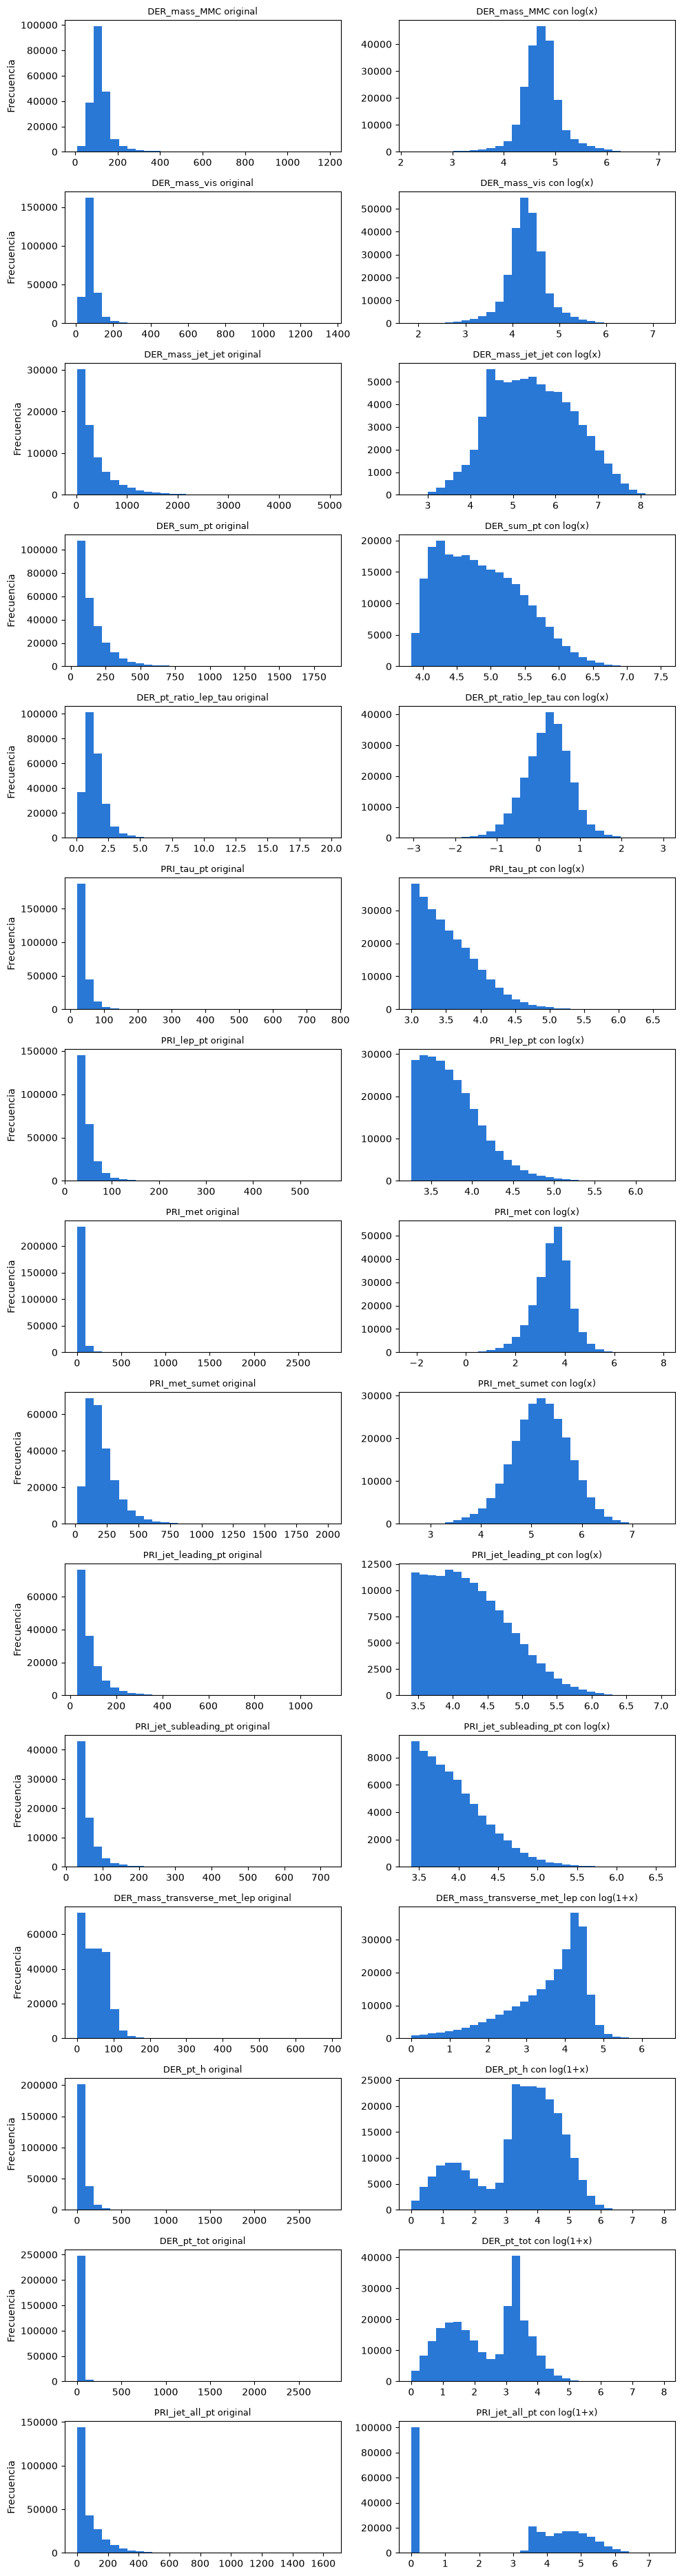

,Transformación,Asimetría original,Asimetría transformada
DER_mass_MMC,log(x),3.807351,0.082358
DER_mass_vis,log(x),3.790262,0.012366
DER_mass_jet_jet,log(x),2.457852,0.138037
DER_sum_pt,log(x),2.320647,0.490004
DER_pt_ratio_lep_tau,log(x),2.633521,-0.201364
PRI_tau_pt,log(x),3.755191,1.027760
PRI_lep_pt,log(x),3.240762,1.020008
PRI_met,log(x),5.270755,-0.625804
PRI_met_sumet,log(x),1.849445,-0.131152
PRI_jet_leading_pt,log(x),2.564700,0.618854


In [242]:
# comprobación de las variables transformadas con logaritmo en Entrenamiento
# Para cada variable: la transformación que se le ha aplicado y su nombre para los títulos
transformaciones = {}
for columna in variables_log:
    transformaciones[columna] = (np.log, "log(x)")
for columna in variables_log1p:
    transformaciones[columna] = (np.log1p, "log(1+x)")


fig, axes = plt.subplots(len(transformaciones), 2, figsize=(10, 2.5 * len(transformaciones)))
for fila, (columna, (funcion, nombre)) in enumerate(transformaciones.items()):
    axes[fila, 0].hist(Entrenamiento_original[columna].dropna(), bins=30, color="#2a78d6")
    axes[fila, 0].set_title(f"{columna} original", fontsize=9)
    axes[fila, 0].set_ylabel("Frecuencia")
    axes[fila, 1].hist(Entrenamiento[columna].dropna(), bins=30, color="#2a78d6")
    axes[fila, 1].set_title(f"{columna} con {nombre}", fontsize=9)

plt.tight_layout()
plt.show()


# Asimetría antes y después: tras aplicar el logaritmo debería acercarse a 0
# Comprobación numérica: los valores guardados coinciden con la transformación aplicada a los originales
resumen = pd.DataFrame({
    "Transformación": [nombre for funcion, nombre in transformaciones.values()],
    "Asimetría original": [Entrenamiento_original[c].skew() for c in transformaciones],
    "Asimetría transformada": [Entrenamiento[c].skew() for c in transformaciones],
}, index=list(transformaciones))
display(resumen)

In [243]:
Entrenamiento[variables] = scaler.fit_transform(Entrenamiento[variables])
Ajuste[variables] = scaler.transform(Ajuste[variables])
Test[variables] = scaler.transform(Test[variables])

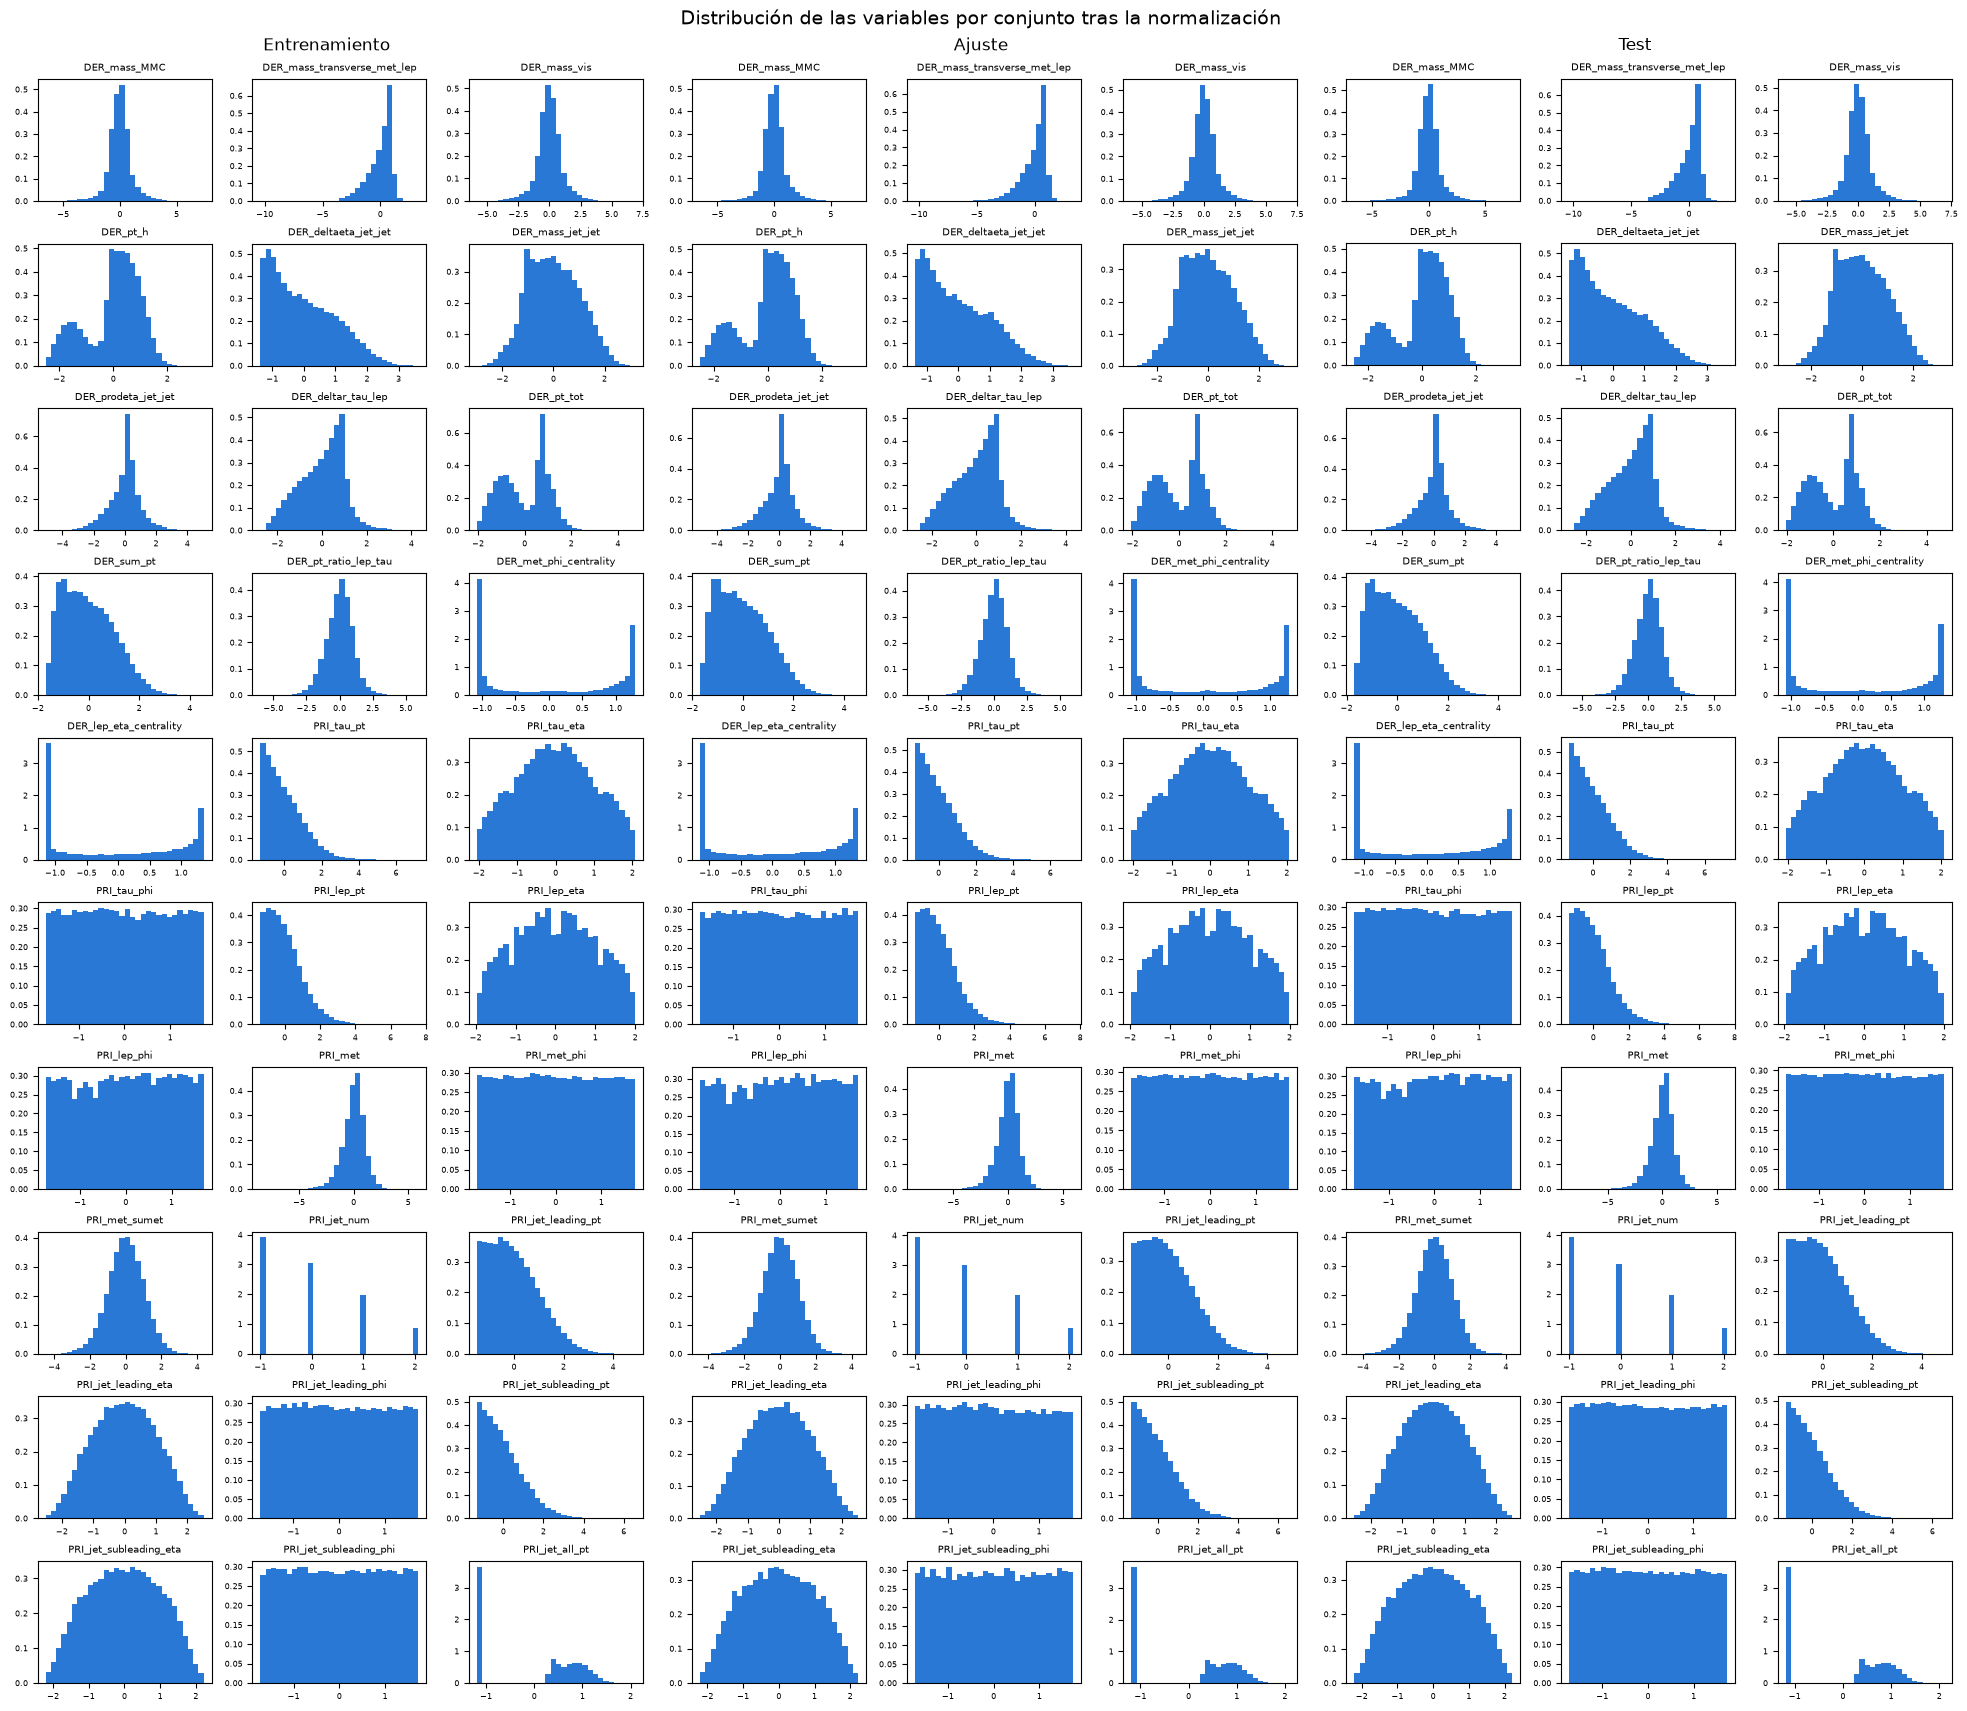

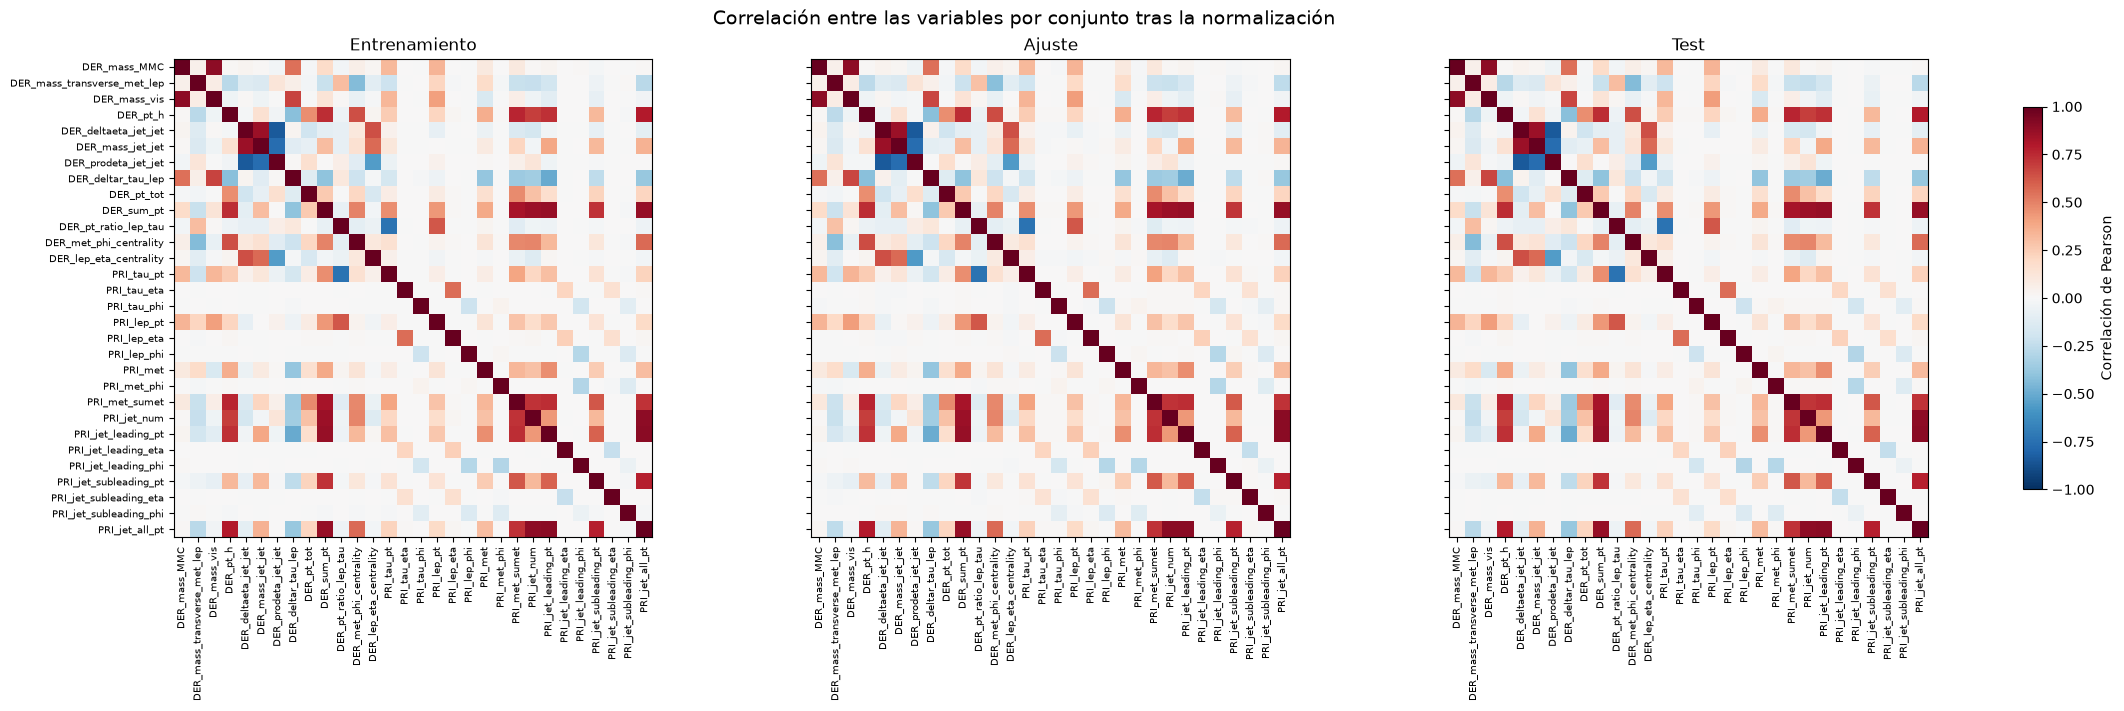

In [244]:
conjuntos = {"Entrenamiento": Entrenamiento, "Ajuste": Ajuste, "Test": Test}

# Solo las variables PRI y DER, que son las que se han transformado con logaritmo y normalizado
# (se quitan el identificador y los pesos, que no se han modificado)
variables_normalizadas = LHC.select_dtypes(include="number").columns.drop(["EventId", "Weight", "KaggleWeight"]).tolist()

columnas = 3
filas = int(np.ceil(len(variables_normalizadas) / columnas))


# HISTOGRAMAS: los tres conjuntos alineados uno al lado del otro
fig = plt.figure(figsize=(19.5, 1.7 * filas), layout="constrained")
subfiguras = fig.subfigures(1, len(conjuntos))

for subfigura, (nombre, datos) in zip(subfiguras, conjuntos.items()):
    subfigura.suptitle(nombre, fontsize=12)
    axes = subfigura.subplots(filas, columnas).ravel()

    for ax, variable in zip(axes, variables_normalizadas):
        # Mismos intervalos en los tres conjuntos, calculados sobre los datos ya normalizados
        # (los de LHC están en la escala original y no sirven para estos datos).
        # Se quitan los NaN (antiguos -999), que no son valores reales y hacen fallar el cálculo
        valores = pd.concat([conjunto[variable] for conjunto in conjuntos.values()]).dropna()
        intervalos = np.histogram_bin_edges(valores, bins=30)
        ax.hist(datos[variable].dropna(), bins=intervalos, density=True, color="#2a78d6")
        ax.set_title(variable, fontsize=7)
        ax.tick_params(labelsize=6)

    for ax in axes[len(variables_normalizadas):]:
        ax.set_visible(False)

fig.suptitle("Distribución de las variables por conjunto tras la normalización", fontsize=14)
plt.show()


# MAPAS DE CORRELACIONES: los tres conjuntos alineados uno al lado del otro
fig, axes = plt.subplots(1, len(conjuntos), figsize=(22, 7), layout="constrained")

for ax, (nombre, datos) in zip(axes, conjuntos.items()):
    corr = datos[variables_normalizadas].corr()  # corr() ya ignora los NaN de cada par de variables
    imagen = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
    ax.set_title(nombre)

# Solo se dejan los nombres del eje Y en el primer mapa
for ax in axes[1:]:
    ax.set_yticks(range(len(corr)), [])

fig.colorbar(imagen, ax=axes, label="Correlación de Pearson", shrink=0.8)
fig.suptitle("Correlación entre las variables por conjunto tras la normalización", fontsize=14)
plt.show()

Y para comparar si cambia algo respecto a la diferenciación de señal y fondo, se va a volver a generar la comparación de distribución entre ambas con sus mapas de correlaciones.

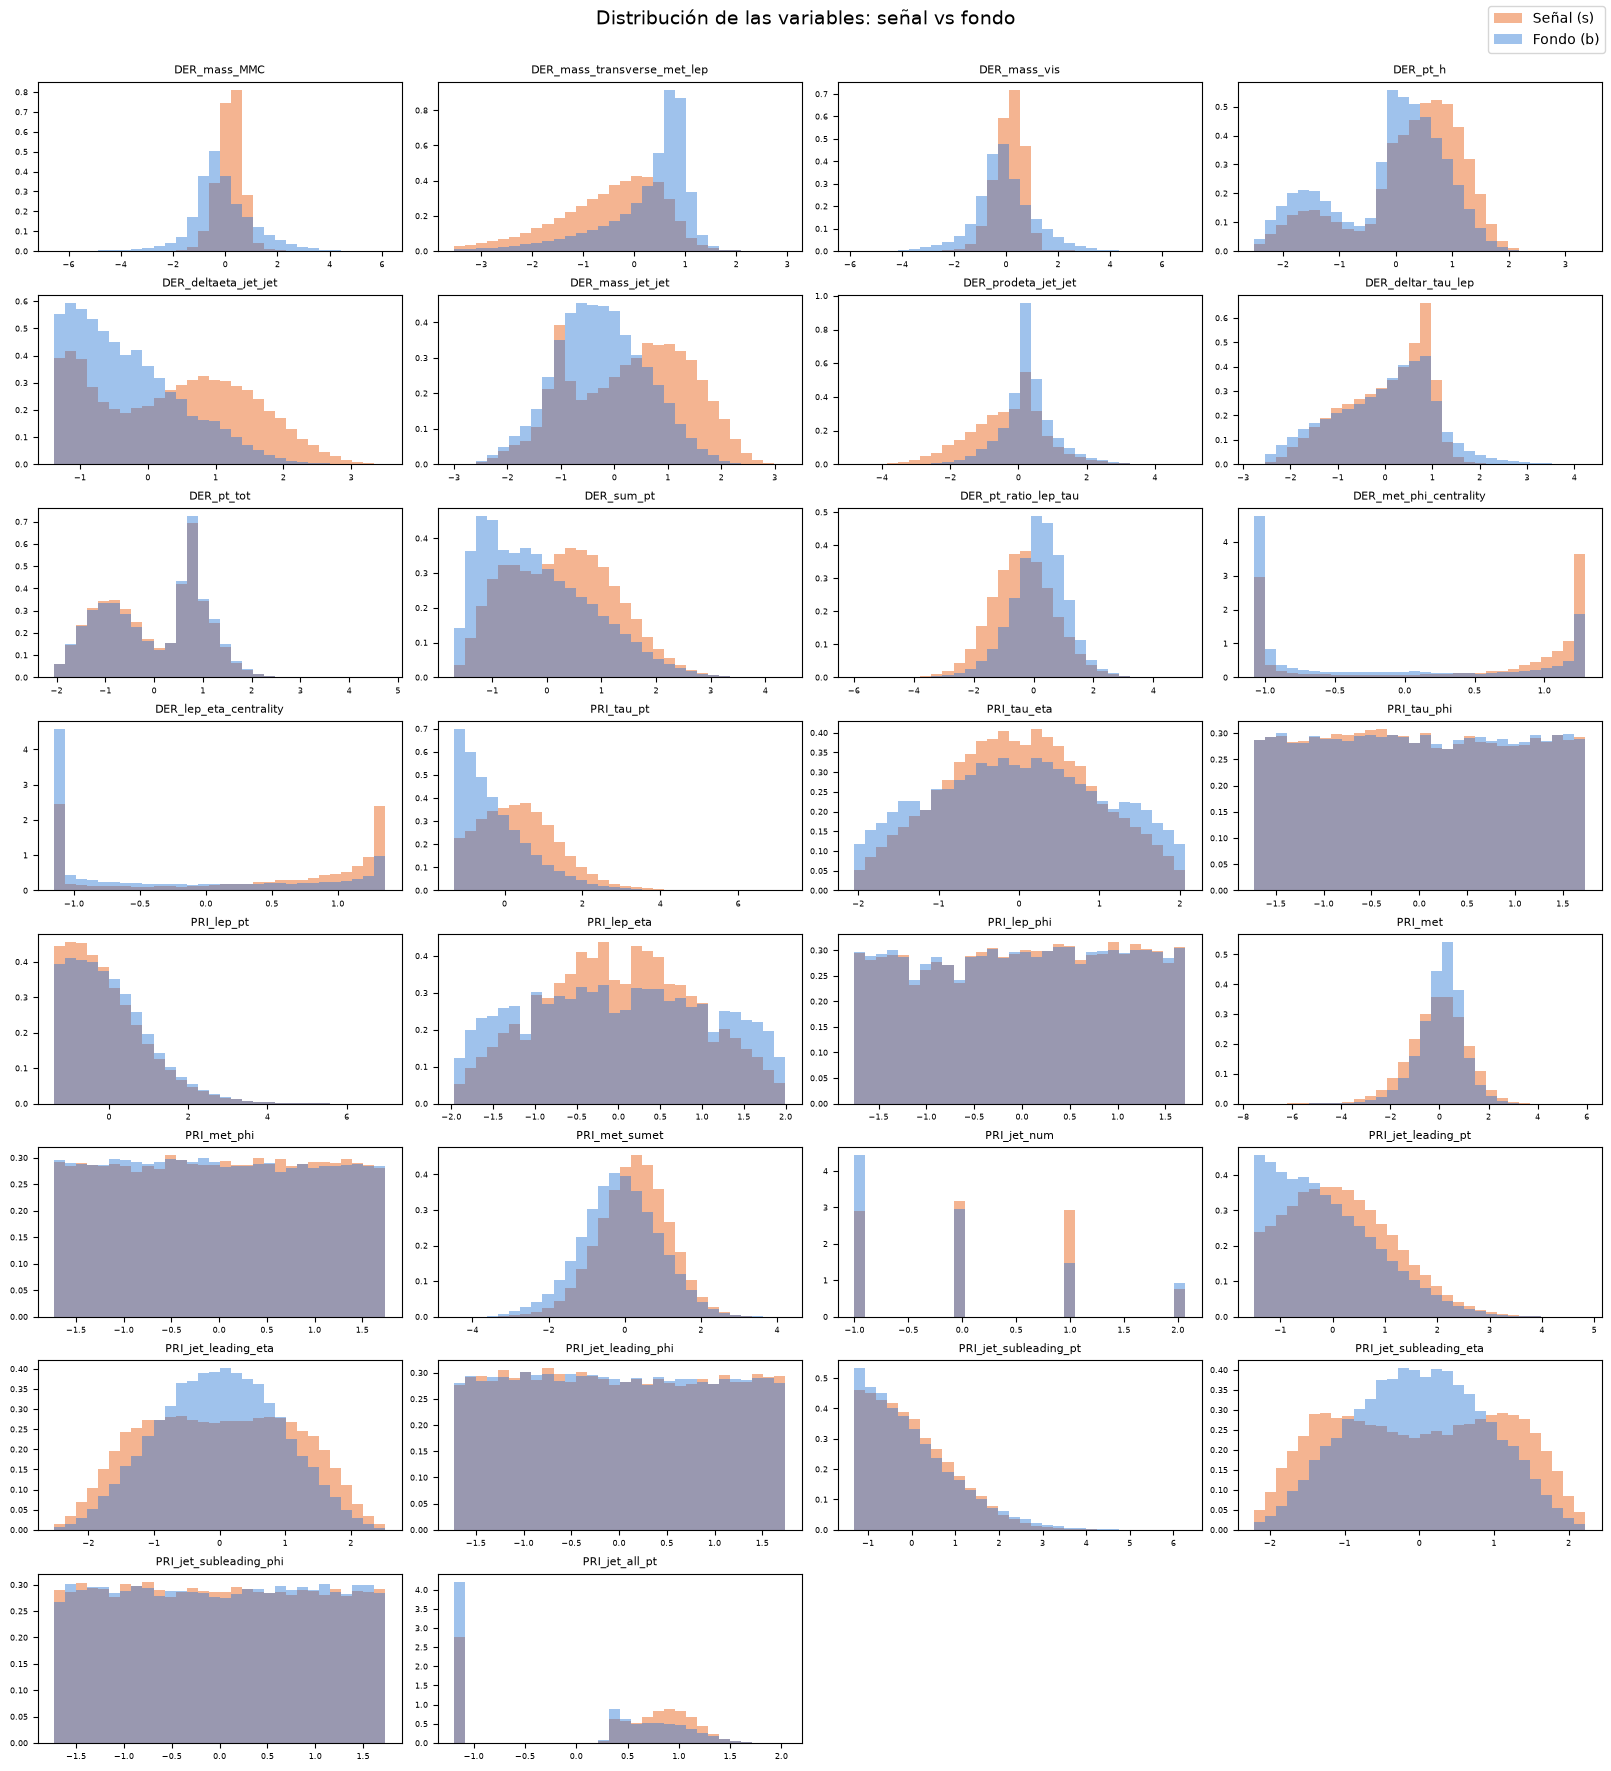

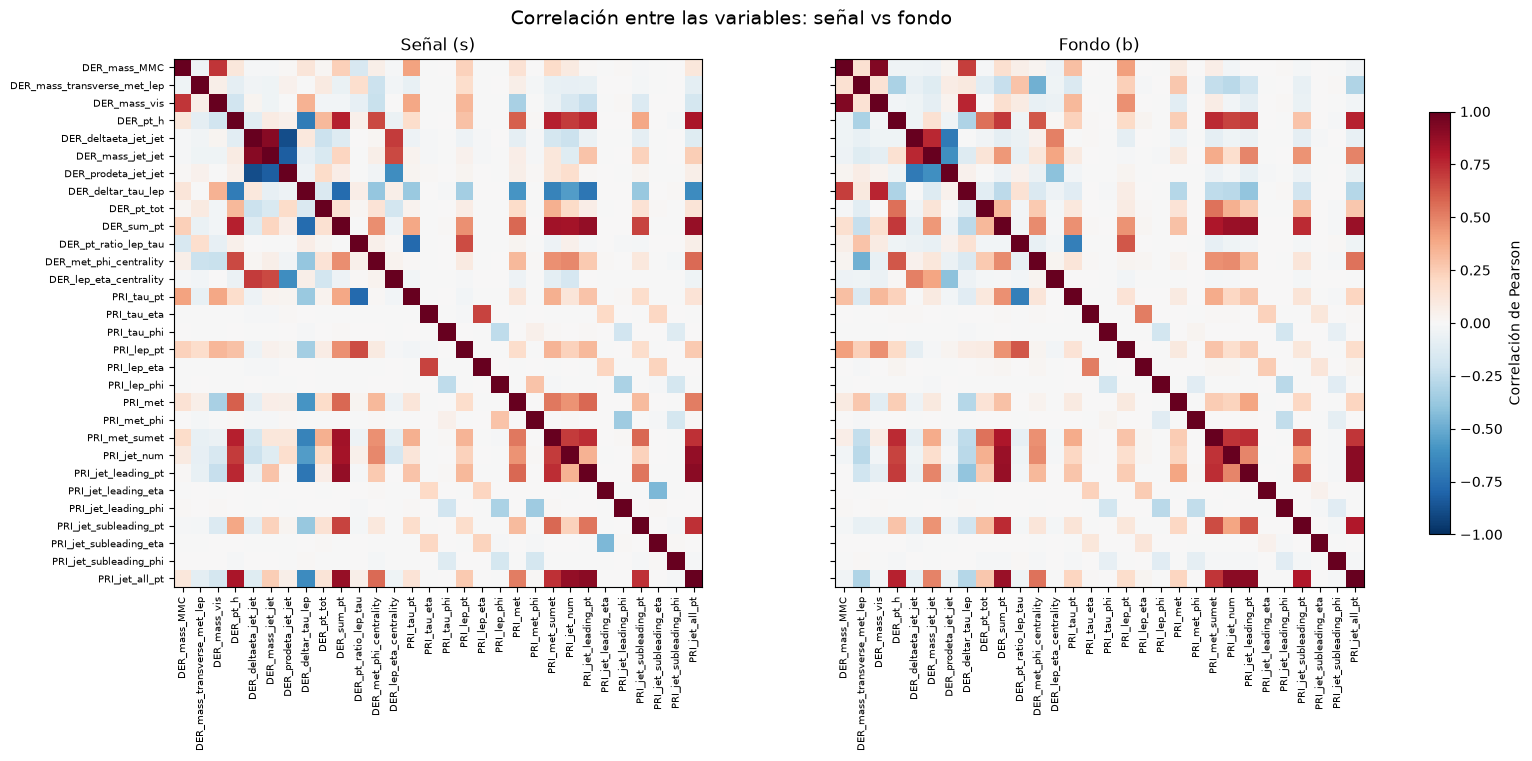

In [245]:
# Se separa todo el LHC según la etiqueta: "s" señal de Higgs y "b" fondo
grupos = {"Señal (s)": Entrenamiento[Entrenamiento["Label"] == "s"], "Fondo (b)": Entrenamiento[Entrenamiento["Label"] == "b"]}
colores = {"Señal (s)": "#e8590c", "Fondo (b)": "#2a78d6"}

# Solo las variables PRI y DER (se quitan el identificador y los pesos, que no son características físicas)
variables = Entrenamiento.select_dtypes(include="number").columns.drop(["EventId", "Weight", "KaggleWeight"]).tolist()

columnas = 4
filas = int(np.ceil(len(variables) / columnas))


# HISTOGRAMAS: señal y fondo superpuestos en el mismo gráfico
fig, axes = plt.subplots(filas, columnas, figsize=(16, 2.2 * filas), layout="constrained")
axes = axes.ravel()

for ax, variable in zip(axes, variables):
    # Mismos intervalos en señal y fondo para poder compararlos
    intervalos = np.histogram_bin_edges(Entrenamiento[variable].dropna(), bins=30)
    for nombre, datos in grupos.items():
        # alpha hace los colores translúcidos para que se vean ambas distribuciones donde se solapan
        ax.hist(datos[variable].dropna(), bins=intervalos, density=True,
                color=colores[nombre], alpha=0.45, label=nombre)
    ax.set_title(variable, fontsize=8)
    ax.tick_params(labelsize=6)

for ax in axes[len(variables):]:
    ax.set_visible(False)

# Una sola leyenda para toda la figura
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper right", fontsize=10)
fig.suptitle("Distribución de las variables: señal vs fondo", fontsize=14)
plt.show()


# MAPAS DE CORRELACIONES: señal y fondo alineados uno al lado del otro
fig, axes = plt.subplots(1, len(grupos), figsize=(16, 7.5), layout="constrained")

for ax, (nombre, datos) in zip(axes, grupos.items()):
    corr = datos[variables].corr()
    imagen = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
    ax.set_title(nombre)

# Solo se dejan los nombres del eje Y en el primer mapa
for ax in axes[1:]:
    ax.set_yticks(range(len(corr)), [])

fig.colorbar(imagen, ax=axes, label="Correlación de Pearson", shrink=0.8)
fig.suptitle("Correlación entre las variables: señal vs fondo", fontsize=14)
plt.show()

Se nota una mejoría en la diferenciación entre señal y fondo, por tanto se puede concluir que el ajuste de logaritmos con la normalización mejoran la clasificación entre señal y fondo.

In [246]:
Entrenamiento.to_csv("Entrenamiento.csv", index=False)
Ajuste.to_csv("Ajuste.csv", index=False)
Test.to_csv("Test.csv", index=False)

Para terminar de analizar, se va a dividir los subconjuntos de Entrenamiento, Ajusta y Test en PRI y PRI + DER.

In [247]:
Entrenamiento = Entrenamiento.replace(np.nan, 0)
Ajuste = Ajuste.replace(np.nan, 0)
Test = Test.replace(np.nan, 0)

In [248]:
Entrenamiento_DER = Entrenamiento.drop(columns=["EventId", "Weight", "KaggleSet", "Label", "KaggleWeight"])
Ajuste_DER = Ajuste.drop(columns=["EventId", "Weight", "KaggleSet", "Label", "KaggleWeight"])
Test_DER = Test.drop(columns=["EventId", "Weight", "KaggleSet", "Label", "KaggleWeight"])

# Se elimina la columna Weight ya que representa los pesos normalizados respecto a todo el conjunto LHC. Ahora los pesos normalizados están en la variable KaggleWeight.
# Se elimina la columna KaggleSet porque ya están dividos y pasa a ser una columna con contenido irrelevante.
# Se elimina la columna Label para que los grupos solo tengan valores numéricos, creando una base de datos de los label respecto de cada eventId
# Se van a descartar los valores del grupo u ya que no se requiere de ningún conjunto más para desarrollar el proyecto.

In [249]:
Entrenamiento_PRI = Entrenamiento_DER[["PRI_tau_pt", "PRI_tau_eta", "PRI_tau_phi","PRI_lep_pt","PRI_lep_eta","PRI_lep_phi","PRI_met","PRI_met_phi","PRI_met_sumet","PRI_jet_num","PRI_jet_leading_pt","PRI_jet_leading_eta","PRI_jet_leading_phi","PRI_jet_subleading_pt", "PRI_jet_subleading_eta","PRI_jet_subleading_phi","PRI_jet_all_pt"]].copy().reset_index(drop=True)
Ajuste_PRI = Ajuste_DER[["PRI_tau_pt", "PRI_tau_eta", "PRI_tau_phi","PRI_lep_pt","PRI_lep_eta","PRI_lep_phi","PRI_met",	"PRI_met_phi","PRI_met_sumet","PRI_jet_num","PRI_jet_leading_pt","PRI_jet_leading_eta","PRI_jet_leading_phi","PRI_jet_subleading_pt", "PRI_jet_subleading_eta",	"PRI_jet_subleading_phi","PRI_jet_all_pt"]].copy().reset_index(drop=True)
Test_PRI = Test_DER[["PRI_tau_pt", "PRI_tau_eta", "PRI_tau_phi","PRI_lep_pt","PRI_lep_eta","PRI_lep_phi","PRI_met",	"PRI_met_phi","PRI_met_sumet","PRI_jet_num","PRI_jet_leading_pt","PRI_jet_leading_eta","PRI_jet_leading_phi","PRI_jet_subleading_pt", "PRI_jet_subleading_eta",	"PRI_jet_subleading_phi","PRI_jet_all_pt"]].copy().reset_index(drop=True)

In [250]:
# Se tiene en cuenta la cantidad de cantidad de valores, suma total de pesos y la cantidad de valores de bosson de Higgs (b) y valores de fondo (s).
print(f"ENTRENAMIENTO\nCantidad de valores:{len(Entrenamiento)}\nSuma total de pesos:{Entrenamiento["Weight"].sum()}\n{Entrenamiento["Label"].value_counts()}\n")  
print(f"AJUSTE\nCantidad de valores:{len(Ajuste)}\nSuma total de pesos:{Ajuste["Weight"].sum()}\n{Ajuste["Label"].value_counts()}\n")
print(f"TEST\nCantidad de valores:{len(Test)}\nSuma total de pesos:{Test["Weight"].sum()}\n{Test["Label"].value_counts()}\n")

ENTRENAMIENTO
Cantidad de valores:250000
Suma total de pesos:125530.31906160462
Label
b    164333
s     85667
Name: count, dtype: int64

AJUSTE
Cantidad de valores:100000
Suma total de pesos:50548.160673219114
Label
b    65975
s    34025
Name: count, dtype: int64

TEST
Cantidad de valores:450000
Suma total de pesos:226424.1456505556
Label
b    296317
s    153683
Name: count, dtype: int64

